## 0. Configuração do Ambiente e Diretório de Trabalho (Google Drive)

Para garantir a persistência dos arquivos intermediários (`data/processed/`) e dos entregáveis (`outputs/`) entre todos os notebooks do pipeline (`01` a `06`) sem necessidade de reenvio manual a cada sessão do Google Colab, montamos o Google Drive e definimos a pasta raiz do projeto (`ifood-growth-competition-case`) como diretório ativo.

> **Nota de reprodutibilidade:** Caso execute este notebook localmente (VS Code / Jupyter), esta célula identifica automaticamente o ambiente local e mantém o diretório raiz do repositório sem exigir montagem do Google Drive.

In [2]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/ifood-growth-competition-case'
    os.makedirs(PROJECT_DIR, exist_ok=True)
    os.chdir(PROJECT_DIR)
    print("Ambiente Google Colab conectado ao Drive:", os.getcwd())
except ImportError:
    # Execução local (VS Code / Jupyter / Terminal)
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    print("Ambiente local detectado:", os.getcwd())

Mounted at /content/drive
Ambiente Google Colab conectado ao Drive: /content/drive/MyDrive/ifood-growth-competition-case


# 02 — Segmentação e Arquétipos Operacionais

**Objetivo:** Classificar as 20 cidades da base real em arquétipos acionáveis, considerando materialidade (`gmv_base_m`), saturação logística (`saturacao_pct`), ocupação (`ocupacao_pct`), market share (`share_pct`), rentabilidade (`margem_base_pct`) e posicionamento competitivo (`price_index_pct`, `frete_gratis_pct`).

**Regras centrais:**
1. **Bloqueio de estímulo bruto de demanda em cidades saturadas (`saturacao_pct > 100%`)**: praças relevantes saturadas (como `City 20`, `City 17`, `City 9`, `City 4`, `City 5`, `City 11`) entram em **Destravamento de Capacidade (Saturada)**, onde a alavanca permitida é **Incentivos para Entregadores / Capacidade** (e não queima de caixa com cupons genéricos).
2. **Defesa sem Guerra de Preço (`share_pct >= 80%`)**: praças com domínio consolidado de mercado (como `City 1`, `City 12`, `City 13`, `City 15`, `City 16`, `City 7`) evitam subsídios agressivos que corroem margem.
3. **Ataque Competitivo / Focalizado**: praças com materialidade relevante, saturação controlada (`<= 100%`) e espaço para ganho de share.


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = ".." if os.path.exists("../data/processed/base_validada.csv") else ("." if os.path.exists("data/processed/base_validada.csv") else "/content")
BASE_PATH = os.path.join(BASE_DIR, "data", "processed", "base_validada.csv")
SEGMENTED_PATH = os.path.join(BASE_DIR, "data", "processed", "base_segmentada.csv")
FIGURES_DIR = os.path.join(BASE_DIR, "outputs", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

df = pd.read_csv(BASE_PATH)

GMV_MIN = 20.0               # Materialidade mínima (R$ 20M) para priorização estratégica
SATURATION_HARD_CAP = 100.0  # Acima de 100% exige destravamento de capacidade
SATURATION_ALERT = 95.0
SHARE_DEFENSE = 80.0         # Acima de 80% de share: defesa de margem sem guerra de preço
MARGIN_ATTACK_MIN = 4.0

print("Base carregada:", df.shape)


Base carregada: (20, 25)


## 1. Classificação das Cidades em Arquétipos


In [4]:
def classify_city(row):
    gmv = float(row["gmv_base_m"])
    sat = float(row["saturacao_pct"])
    op_margin = float(row["margem_base_pct"])
    share = float(row["share_pct"])

    # 1. Praças saturadas (> 100%)
    if sat > SATURATION_HARD_CAP:
        if gmv >= GMV_MIN:
            return "Destravamento de Capacidade (Saturada)"
        return "Bloqueio por Saturação (Baixa Materialidade)"

    # 2. Baixa materialidade (< R$ 20M)
    if gmv < GMV_MIN:
        if share >= SHARE_DEFENSE:
            return "Defesa sem Guerra de Preço"
        return "Fora de Escopo por Materialidade"

    # 3. Liderança consolidada (share >= 80%)
    if share >= SHARE_DEFENSE:
        return "Defesa sem Guerra de Preço"

    # 4. Operating Margin negativa: turnaround estrutural antes de acelerar
    if op_margin < 0:
        return "Turnaround Estrutural"

    # 5. Margem saudável e capacidade disponível: ataque
    if op_margin >= MARGIN_ATTACK_MIN:
        if sat >= SATURATION_ALERT:
            return "Ataque Focalizado (Alerta Capacidade)"
        return "Ataque Competitivo"

    return "Turnaround Estrutural"

df["arquetipo_operacional"] = df.apply(classify_city, axis=1)

# Elegível a investimento de demanda (somente praças não saturadas <= 100% com tese econômica)
df["elegivel_demanda"] = df["arquetipo_operacional"].isin([
    "Ataque Competitivo",
    "Ataque Focalizado (Alerta Capacidade)",
    "Turnaround Estrutural"
])

# Elegível a investimento exclusivo de capacidade logística (praças relevantes > 100% saturação)
df["elegivel_capacidade"] = df["arquetipo_operacional"].isin([
    "Destravamento de Capacidade (Saturada)",
    "Ataque Focalizado (Alerta Capacidade)"
])

display(df.sort_values("gmv_base_m", ascending=False)[[
    "cidade", "gmv_base_m", "pedidos_base_k", "saturacao_pct", "ocupacao_pct",
    "share_pct", "margem_contribuicao_pct", "margem_base_pct", "price_index_pct",
    "arquetipo_operacional", "elegivel_demanda", "elegivel_capacidade"
]])


,cidade,gmv_base_m,pedidos_base_k,saturacao_pct,ocupacao_pct,share_pct,margem_contribuicao_pct,margem_base_pct,price_index_pct,arquetipo_operacional,elegivel_demanda,elegivel_capacidade
12,City 20,635.776558,7443.81873,141.21,47.54,74.0,8.03,4.78,114.44,Destravamento de Capacidade (Saturada),False,True
8,City 17,162.615089,2003.38905,131.38,57.83,67.0,7.38,-1.34,108.99,Destravamento de Capacidade (Saturada),False,True
13,City 3,101.207940,1318.84206,79.81,40.71,76.0,8.22,6.06,101.27,Ataque Competitivo,True,False
11,City 2,87.773466,1213.68177,83.86,60.18,67.0,8.96,8.41,116.84,Ataque Competitivo,True,False
16,City 6,63.312576,893.99289,96.50,65.89,68.0,7.83,7.09,111.73,Ataque Focalizado (Alerta Capacidade),True,True
19,City 9,60.758945,901.86945,165.28,41.49,78.0,7.50,5.90,104.94,Destravamento de Capacidade (Saturada),False,True
14,City 4,52.163074,793.35474,129.05,54.51,73.0,7.78,3.39,96.61,Destravamento de Capacidade (Saturada),False,True
9,City 18,41.916676,630.70533,78.48,45.01,65.0,7.72,-4.69,93.49,Turnaround Estrutural,True,False
6,City 15,39.211583,562.25385,86.18,56.72,91.0,7.29,0.07,95.50,Defesa sem Guerra de Preço,False,False
0,City 1,22.126920,329.46576,71.38,50.19,93.0,8.16,-0.01,91.07,Defesa sem Guerra de Preço,False,False


## 2. Resumo Consolidado por Arquétipo


In [5]:
archetype_summary = (
    df.groupby("arquetipo_operacional", as_index=False)
    .agg(
        cidades=("cidade", "count"),
        gmv_total_m=("gmv_base_m", "sum"),
        pedidos_total_k=("pedidos_base_k", "sum"),
        margem_op_total_m=("margem_base_m", "sum"),
        saturacao_media_pct=("saturacao_pct", "mean"),
        share_medio_pct=("share_pct", "mean")
    )
    .sort_values("gmv_total_m", ascending=False)
)
archetype_summary["pct_gmv_total"] = (archetype_summary["gmv_total_m"] / df["gmv_base_m"].sum()) * 100.0
archetype_summary["operating_margin_pond_pct"] = (archetype_summary["margem_op_total_m"] / archetype_summary["gmv_total_m"]) * 100.0

display(archetype_summary)


,arquetipo_operacional,cidades,gmv_total_m,pedidos_total_k,margem_op_total_m,saturacao_media_pct,share_medio_pct,pct_gmv_total,operating_margin_pond_pct
4,Destravamento de Capacidade (Saturada),4,911.313666,11142.43197,33.564183,141.730000,73.000000,65.624365,3.683055
0,Ataque Competitivo,2,188.981406,2532.52383,13.514950,81.835000,71.500000,13.608690,7.151471
3,Defesa sem Guerra de Preço,7,141.493292,2021.63634,2.566924,83.295714,89.142857,10.189036,1.814167
1,Ataque Focalizado (Alerta Capacidade),1,63.312576,893.99289,4.488862,96.500000,68.000000,4.559185,7.090000
6,Turnaround Estrutural,1,41.916676,630.70533,-1.965892,78.480000,65.000000,3.018451,-4.690000
2,Bloqueio por Saturação (Baixa Materialidade),4,38.822069,585.35184,3.002645,134.697500,76.000000,2.795606,7.734376
5,Fora de Escopo por Materialidade,1,2.842198,37.38258,0.183606,98.820000,65.000000,0.204669,6.460000


## 3. Visualização: Materialidade vs. Capacidade Logística


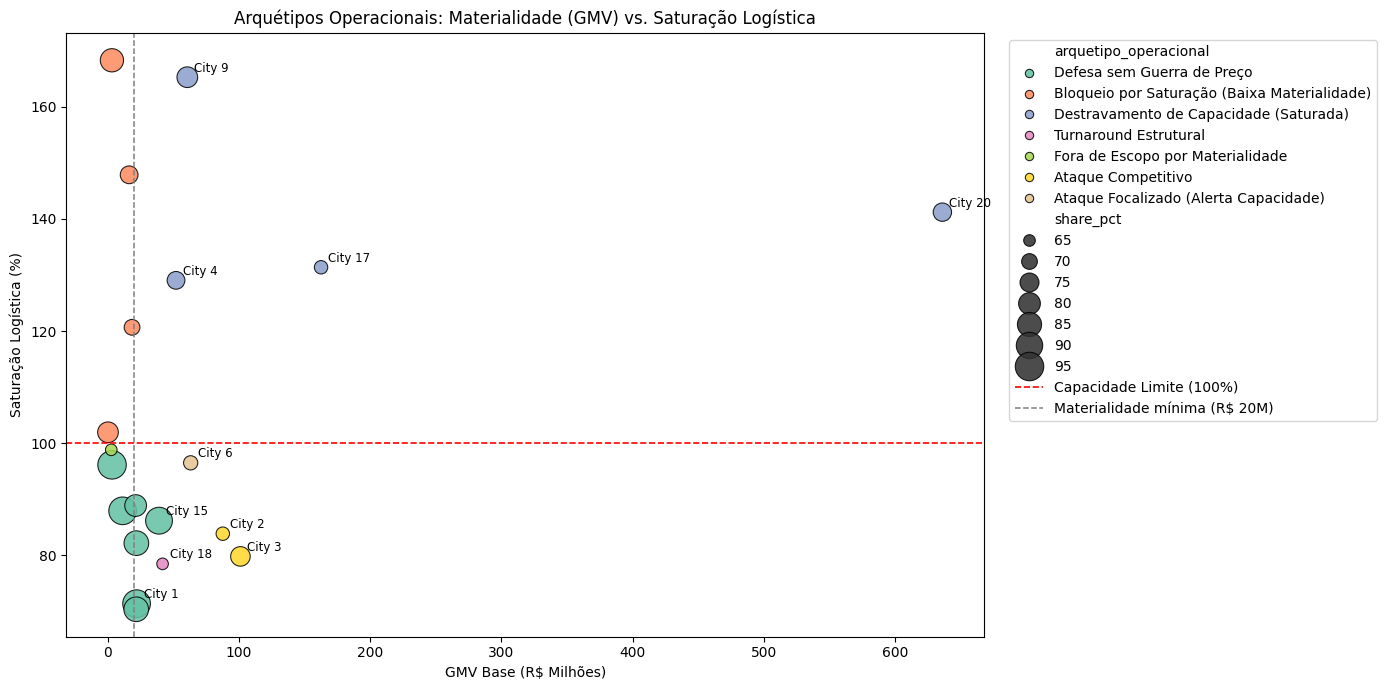

In [6]:
plt.figure(figsize=(14, 7))
sns.scatterplot(
    data=df,
    x="gmv_base_m",
    y="saturacao_pct",
    hue="arquetipo_operacional",
    size="share_pct",
    sizes=(70, 420),
    palette="Set2",
    edgecolor="black",
    alpha=0.88
)

plt.axhline(SATURATION_HARD_CAP, color="red", linestyle="--", linewidth=1.2, label="Capacidade Limite (100%)")
plt.axvline(GMV_MIN, color="gray", linestyle="--", linewidth=1.1, label=f"Materialidade mínima (R$ {GMV_MIN:.0f}M)")

for _, r in df.sort_values("gmv_base_m", ascending=False).head(10).iterrows():
    plt.annotate(r["cidade"], (r["gmv_base_m"], r["saturacao_pct"]), fontsize=8.5, xytext=(5, 4), textcoords="offset points")

plt.title("Arquétipos Operacionais: Materialidade (GMV) vs. Saturação Logística")
plt.xlabel("GMV Base (R$ Milhões)")
plt.ylabel("Saturação Logística (%)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "02_arquetipos_operacionais.png"), bbox_inches="tight", dpi=150)
plt.show()


## 4. Exportação da Base Segmentada


In [7]:
df.to_csv(SEGMENTED_PATH, index=False)
print("Base segmentada salva em:", SEGMENTED_PATH)


Base segmentada salva em: ./data/processed/base_segmentada.csv
